In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


# kagglehub.dataset_download('<owner>/<dataset-slug>')

buat variable untuk 

In [3]:
TRAIN_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/train.csv'
TEST_PATH  = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/test.csv'
SAMPLE_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/sample_submission.csv'
VALID_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/valid.csv'

_tr = pd.read_csv(TRAIN_PATH)
_te = pd.read_csv(TEST_PATH)
_valid = pd.read_csv(VALID_PATH)

sample = pd.read_csv(SAMPLE_PATH)

N_TRAIN = len(_tr)
N_VALID = len(_valid)

# gabungkan train + test agar cleaning identik; baris test punya target NaN
df_train = pd.concat([_tr, _te, _valid], ignore_index=True)
print(df_train.shape, N_TRAIN, N_VALID)

(7865, 15) 4728 1200


In [4]:
pd.set_option('display.max_rows', 100)

# EDA

### Cek Missing Value

In [5]:
df_train.isna().sum()

Id                         0
month                      0
day_of_week                0
hour                       0
temperature_c            192
humidity_pct             167
wind_speed_ms            190
visibility_10m           206
dew_point_c              215
solar_radiation_mjm2     193
rainfall_mm              189
snowfall_cm              189
season                     0
holiday                    0
rented_bike_count       1937
dtype: int64

In [6]:
df_train[:N_TRAIN]

,Id,month,day_of_week,hour,temperature_c,humidity_pct,wind_speed_ms,visibility_10m,dew_point_c,solar_radiation_mjm2,rainfall_mm,snowfall_cm,season,holiday,rented_bike_count
0,bk_754f4e10a46336bbbcb9,2,3,14,4.89,49.60,4.11,1174.74,-4.86,1.08,0.0,0.0,Winter,No Holiday,331.0
1,bk_b173e94a44f9021b66a8,2,6,15,-2.40,29.84,2.69,NaN,-17.57,1.38,0.0,0.0,Winter,No Holiday,181.0
2,bk_c2929a145ff14a2b66eb,7,4,14,29.60,62.87,2.77,1923.20,21.52,1.77,0.0,0.0,Summer,No Holiday,999.0
3,bk_bfb1af02d9c8a82b7051,11,2,21,4.33,32.29,1.20,1760.17,-11.32,0.00,0.0,0.0,Autumn,No Holiday,846.0
4,bk_4111f3bffd8d14296138,5,0,19,22.99,56.29,1.91,562.78,13.70,0.32,0.0,0.0,Spring,No Holiday,2236.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4723,bk_84e9a6ed77b2f307f024,3,1,12,8.60,35.21,1.94,1882.53,-6.46,2.55,0.0,0.0,Spring,No Holiday,504.0
4724,bk_d40c324e5d23ca6c9668,12,5,3,-4.52,28.86,0.57,2000.00,-13.98,0.00,0.0,0.0,Winter,No Holiday,169.0
4725,bk_0f2636467311bb65e185,9,0,9,20.37,67.31,NaN,1714.89,13.86,1.13,0.0,0.0,Autumn,No Holiday,1185.0
4726,bk_1868b11a663872ff1d8b,11,4,23,2.02,32.54,1.49,1960.57,-12.83,0.00,0.0,0.0,Autumn,No Holiday,548.0


### Cek target

C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1454025781.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1454025781.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=_tr, x="season", order=month, ax=axes[1, 0], palette="Set2")


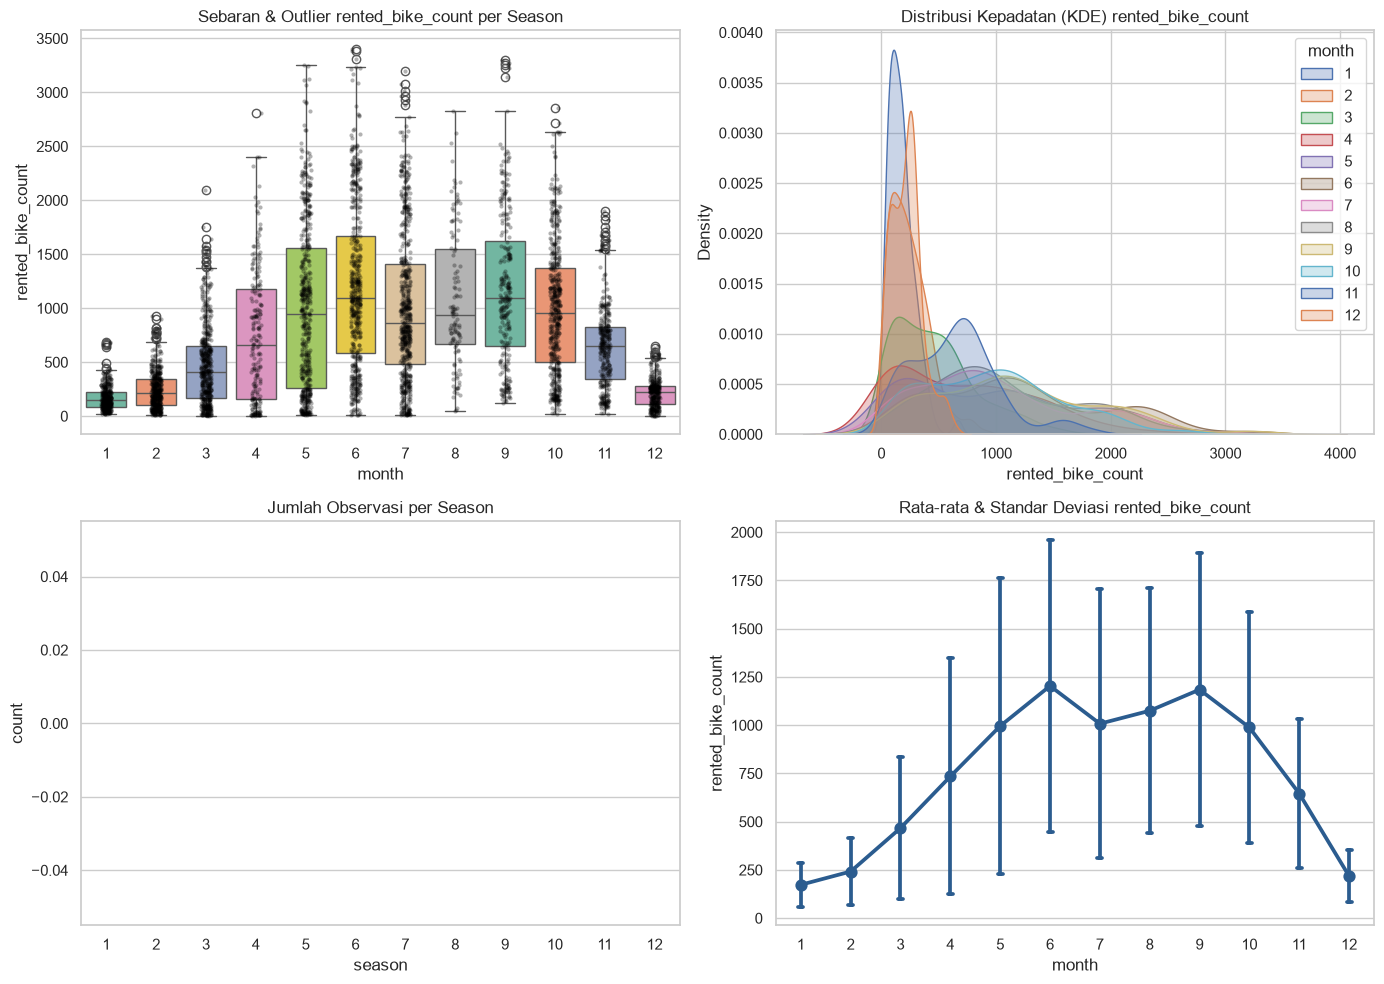

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# seasons = [1,2,3,4]
seasons = ["Spring","Summer","Autumn","Winter"]
month = [1,2,3,4,5,6,7,8,9,10,11,12]

xvalue = "month"
yvalue = "rented_bike_count"


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier rented_bike_count per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in month:
    subset = _tr[_tr[xvalue] == musim]["rented_bike_count"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) rented_bike_count")
axes[0, 1].legend(title=xvalue)

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=_tr, x="season", order=month, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi rented_bike_count")

plt.tight_layout()
plt.show()

C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1846741700.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1846741700.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=_tr, x="season", order=month, ax=axes[1, 0], palette="Set2")


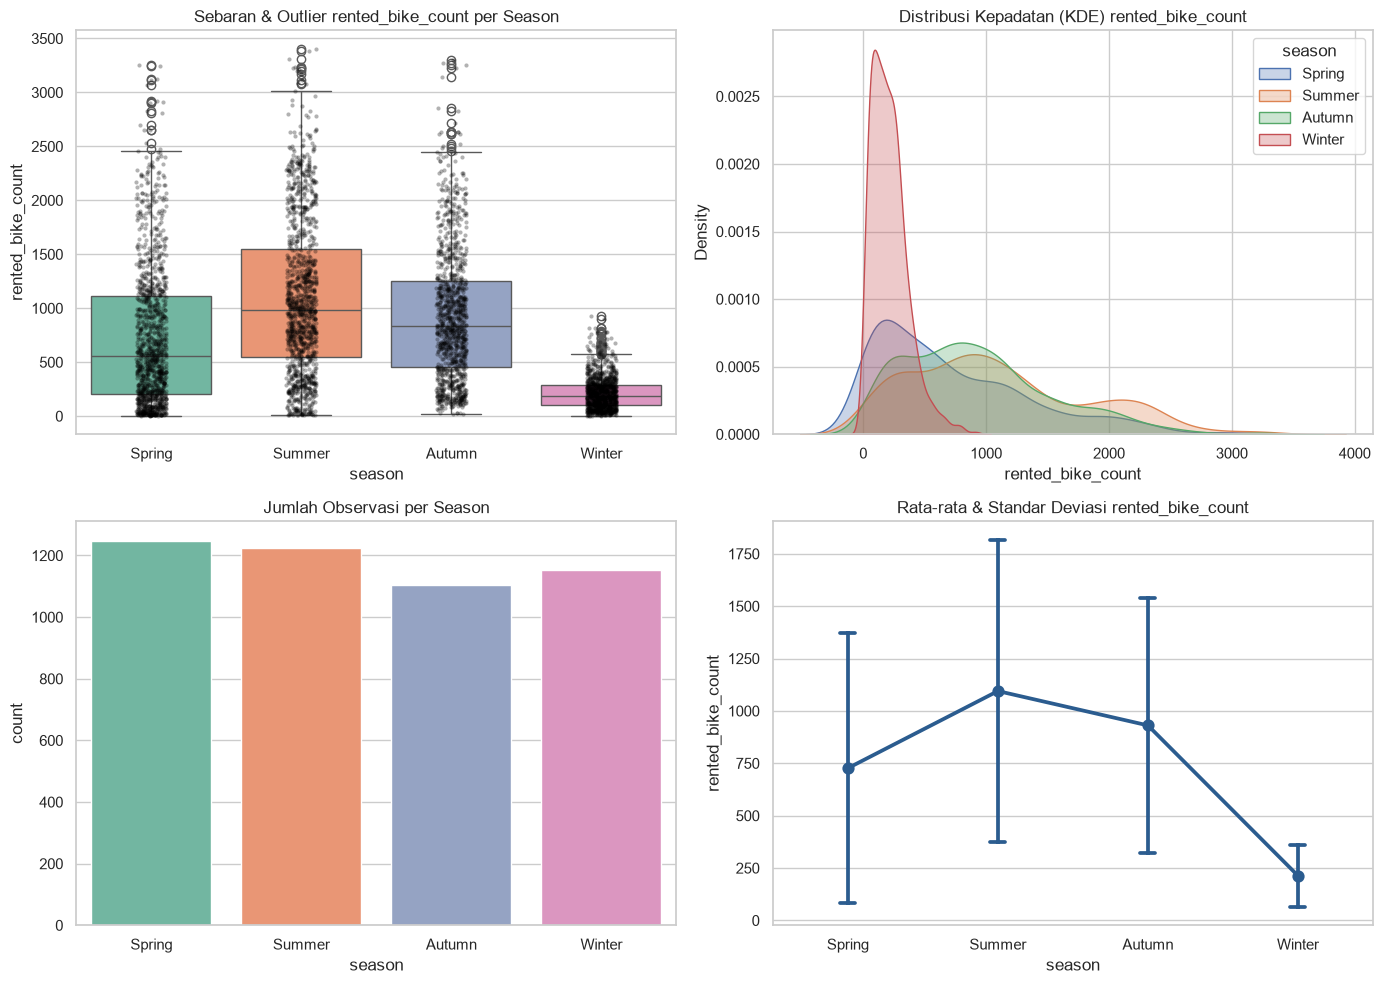

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# seasons = [1,2,3,4]
month = ["Spring","Summer","Autumn","Winter"]

xvalue = "season"


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier rented_bike_count per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in month:
    subset = _tr[_tr[xvalue] == musim]["rented_bike_count"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) rented_bike_count")
axes[0, 1].legend(title=xvalue)

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=_tr, x="season", order=month, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=_tr, x=xvalue, y="rented_bike_count", order=month,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi rented_bike_count")

plt.tight_layout()
plt.show()

### Cek suhu 
Cek apakah ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1781903856.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1781903856.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")


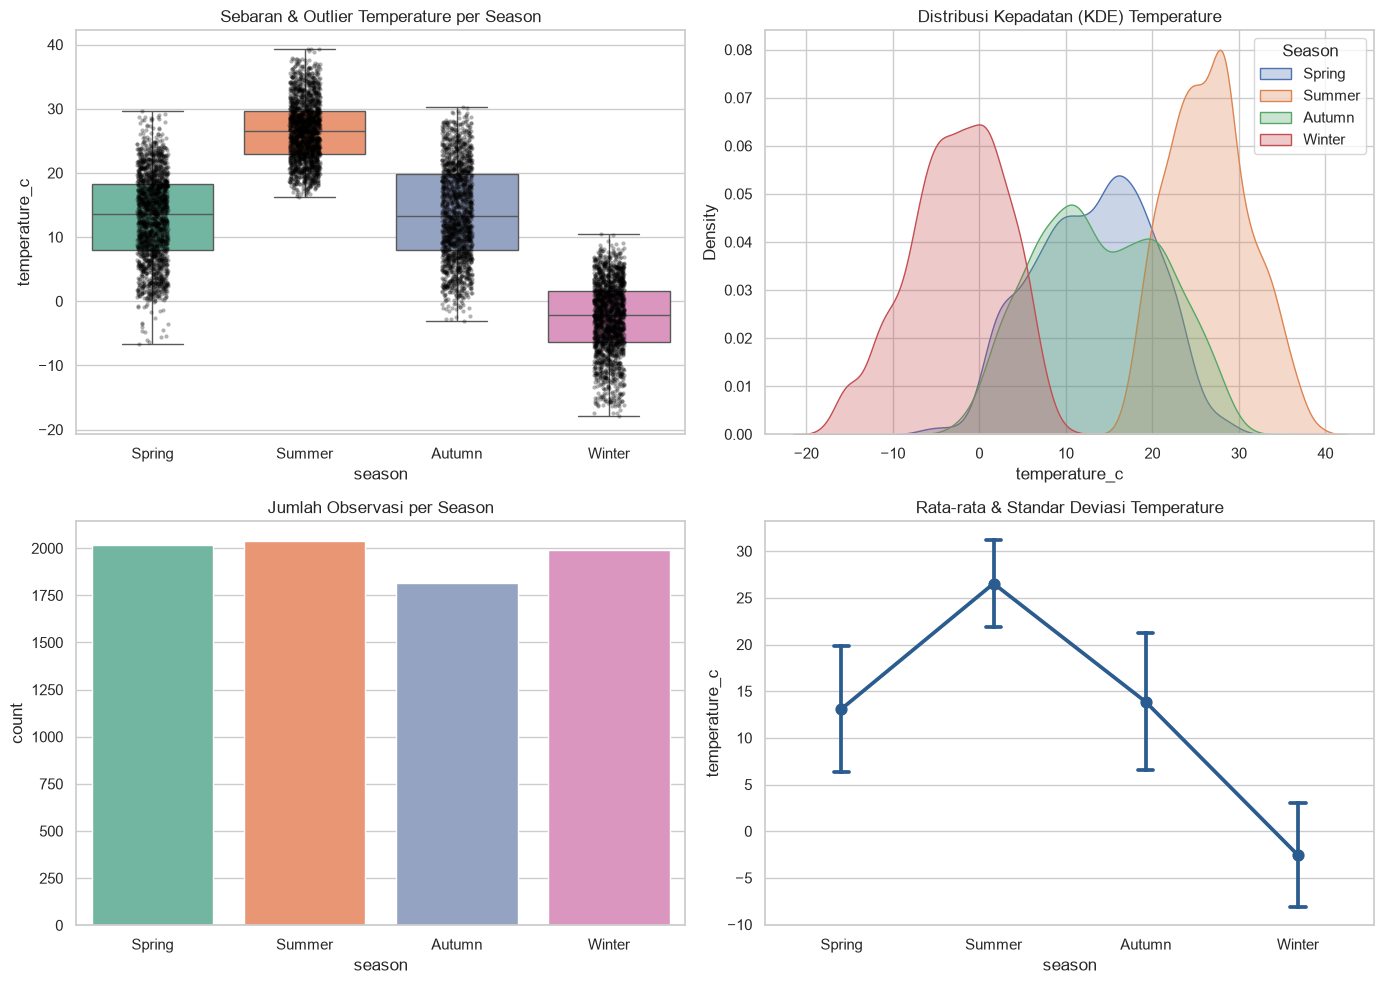

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# seasons = [1,2,3,4]
seasons = ["Spring","Summer","Autumn","Winter"]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in seasons:
    subset = df_train[df_train["season"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="Season")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="season", y="temperature_c", order=seasons,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

Kita cek ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1980772207.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_9372\1980772207.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")


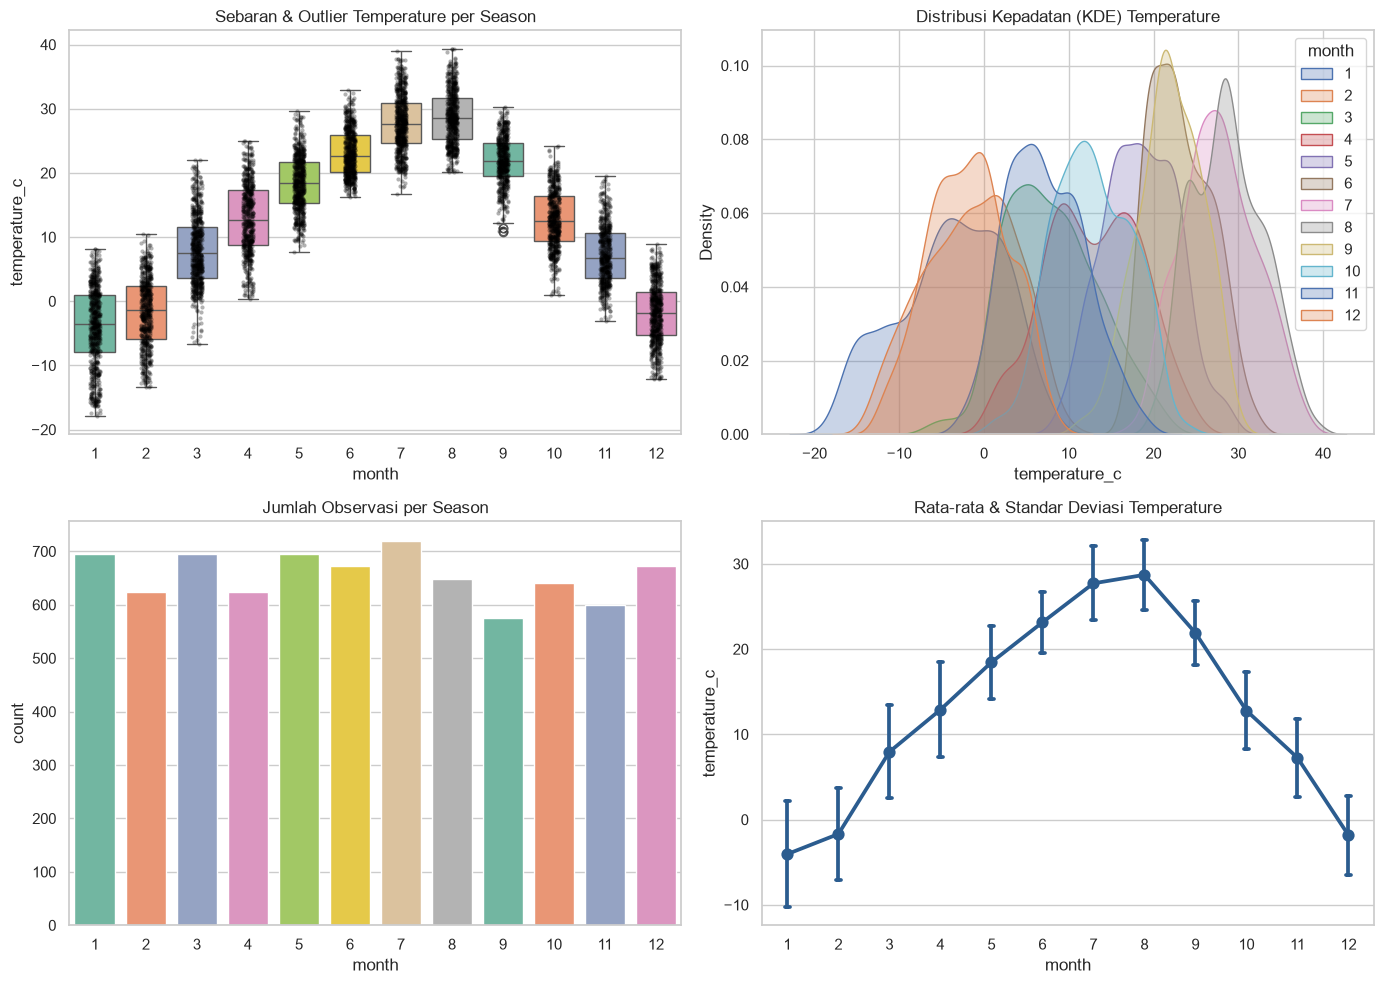

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

month = [1,2,3,4,5,6,7,8,9,10,11,12]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in month:
    subset = df_train[df_train["month"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="month")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="month", y="temperature_c", order=month,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

### Cek kecocokan antara musim dan bulan

In [11]:
ct = pd.crosstab(df_train['month'], df_train['season'], margins=True)
print(ct)

season  Autumn  Spring  Summer  Winter   All
month                                       
1            0       0       0     696   696
2            0       0       0     624   624
3            0     696       0       0   696
4            0     624       0       0   624
5            0     696       0       0   696
6            0       0     672       0   672
7            0       0     720       0   720
8            0       0     648       0   648
9          576       0       0       0   576
10         641       0       0       0   641
11         600       0       0       0   600
12           0       0       0     672   672
All       1817    2016    2040    1992  7865


Hasil ternyata cocok semua tidak ada data yang tidak cocok

Skewness Asli  : 1.1673
Skewness log1p : -0.7848
Skewness sqrt  : 0.3581


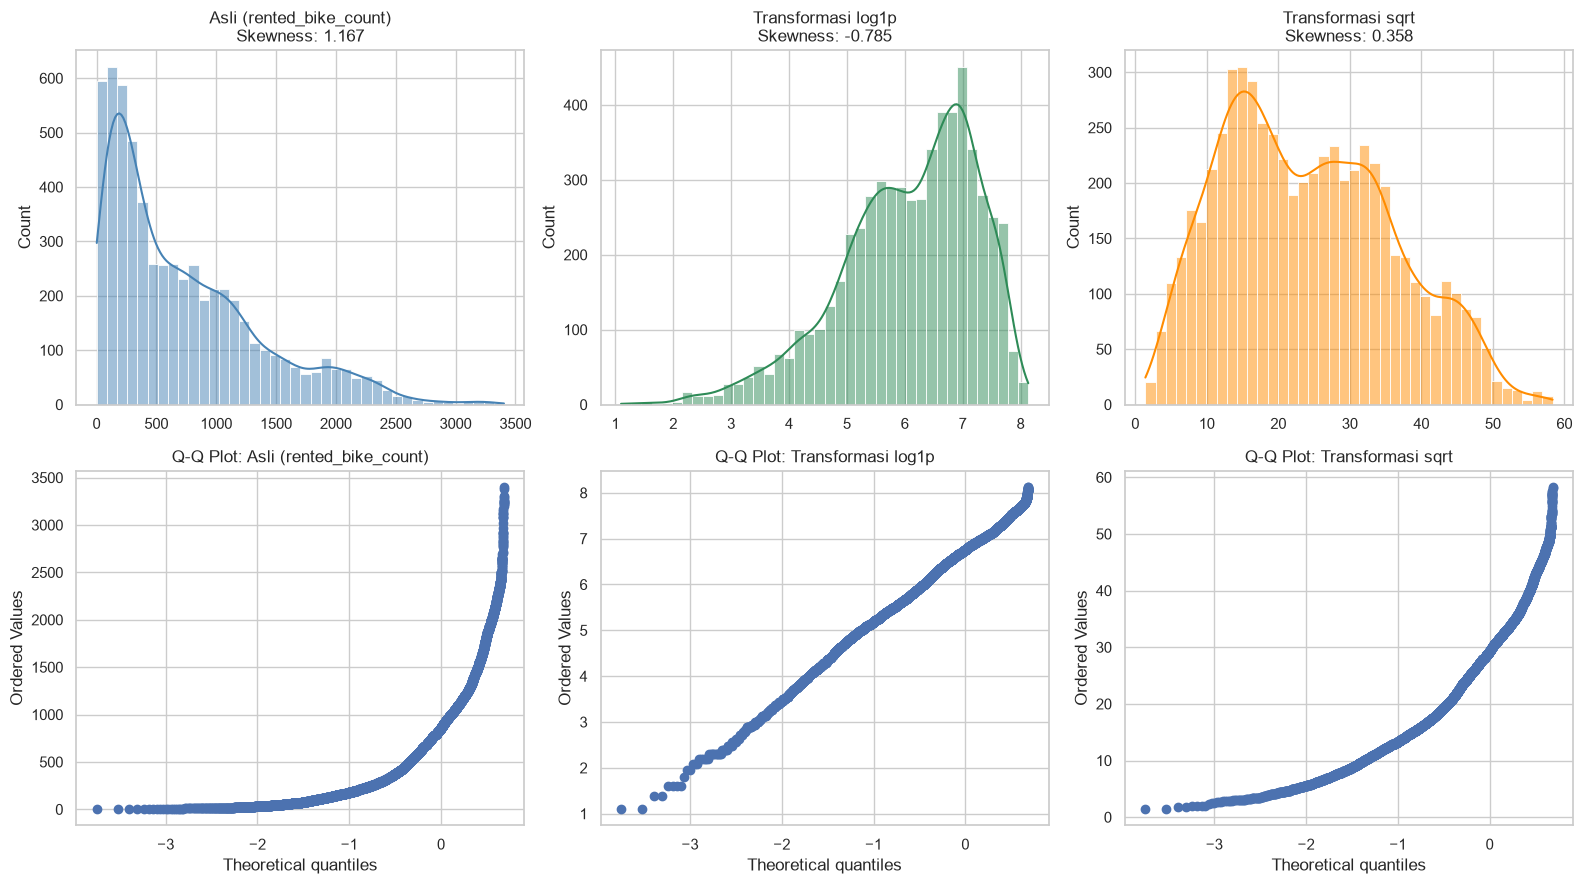

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

y = df_train['rented_bike_count']
y_log = np.log1p(y)
y_sqrt = np.sqrt(y)

# 1. Hitung nilai skewness secara kuantitatif
print(f"Skewness Asli  : {y.skew():.4f}")
print(f"Skewness log1p : {y_log.skew():.4f}")
print(f"Skewness sqrt  : {y_sqrt.skew():.4f}")

# 2. Visualisasi Histogram + KDE (baris atas) dan Q-Q Plot (baris bawah)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

variants = [
    (y, 'Asli (rented_bike_count)', 'steelblue'),
    (y_log, 'Transformasi log1p', 'seagreen'),
    (y_sqrt, 'Transformasi sqrt', 'darkorange')
]

for i, (data, title, color) in enumerate(variants):
    # Baris 1: Histogram + KDE
    sns.histplot(data, kde=True, ax=axes[0, i], color=color, bins=40)
    axes[0, i].set_title(f"{title}\nSkewness: {data.skew():.3f}")
    axes[0, i].set_xlabel("")
    
    # Baris 2: Q-Q Plot terhadap distribusi normal
    stats.probplot(data, dist="norm", plot=axes[1, i])
    axes[1, i].set_title(f"Q-Q Plot: {title}")

plt.tight_layout()
plt.show()

# Data Cleaning

### Column Holiday
Replace "holiday" -> 1 and "No holiday" -> 0

In [13]:
df_train['holiday'] = df_train['holiday'].replace('No Holiday','0').replace('Holiday','1').astype(int)
df_train['holiday'].value_counts()

holiday
0    7481
1     384
Name: count, dtype: int64

### Column Seasons

In [14]:
df_train['season'] = df_train['season'].replace('Spring','0').replace('Summer','1').replace('Winter','2').replace('Autumn','3').astype(int)
df_train['season'].value_counts()

season
1    2040
0    2016
2    1992
3    1817
Name: count, dtype: int64

### Missing Value

In [15]:
column = {
    'humidity_pct',
    'wind_speed_ms',
    'visibility_10m',
    'dew_point_c',
    'solar_radiation_mjm2',
    'rainfall_mm',
    'snowfall_cm'}

for i in column:
    df_train[i] = df_train[i].fillna(df_train.groupby("season")[i].transform("median"))

Mengisi Misiing valude `temperature_c` dengan rata rata untuk setiap seasons

In [16]:
df_train["temperature_c"] = df_train["temperature_c"].fillna(
    df_train.groupby("season")["temperature_c"].transform("median"))

# Feature Engineering

buat fitur anomali relatif perbulan

In [17]:
month_mean = df_train.groupby("month")["temperature_c"].transform("mean")
month_std = df_train.groupby("month")["temperature_c"].transform("std")

df_train["temp_zscore_month"] = (df_train["temperature_c"] - month_mean) / month_std

Ubah Fitur `month` dan fitur `hour` menjadi fitur sinus supaya model bisa mengenali siklus dari hari dan bulan.

In [18]:
df_train["month_sin"] = np.sin(2 * np.pi * df_train["month"] / 12)
df_train["month_cos"] = np.cos(2 * np.pi * df_train["month"] / 12)

df_train["hour_sin"] = np.sin(2 * np.pi * df_train["hour"] / 24)
df_train["hour_cos"] = np.cos(2 * np.pi * df_train["hour"] / 24)

df_train["season_sin"] = np.sin(2 * np.pi * df_train["season"] / 4)
df_train["season_cos"] = np.cos(2 * np.pi * df_train["season"] / 4)

Buat fitur baru "is_weekend"

In [19]:
df_train["is_weekend"] = df_train["day_of_week"].isin([5, 6]).astype(int)

# Model Training

karena diawal kita mengabungkan antara train data dan test data maka kita pisahkan kembali keduanya

In [20]:
train_clean = df_train.iloc[:N_TRAIN].copy()
test_clean = df_train.iloc[N_TRAIN:N_TRAIN+N_VALID].drop(columns=['rented_bike_count']).reset_index(drop=True)
valid_clean = df_train.iloc[N_TRAIN+N_VALID:].copy()

Buat variable fitur berisi fitur fitur apa saja yang akan digunakan pada train data

In [21]:
features = train_clean.select_dtypes(include=[np.number]).columns.drop(['id', 'rented_bike_count'], errors='ignore')
features

Index(['month', 'day_of_week', 'hour', 'temperature_c', 'humidity_pct',
       'wind_speed_ms', 'visibility_10m', 'dew_point_c',
       'solar_radiation_mjm2', 'rainfall_mm', 'snowfall_cm', 'season',
       'holiday', 'temp_zscore_month', 'month_sin', 'month_cos', 'hour_sin',
       'hour_cos', 'season_sin', 'season_cos', 'is_weekend'],
      dtype='str')

### Try several model

In [22]:
# from sklearn.linear_model import Lasso, LinearRegression, Ridge
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# from sklearn.model_selection import train_test_split
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.neural_network import MLPRegressor
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.svm import SVR
# from sklearn.ensemble import (
#     HistGradientBoostingRegressor, 
#     RandomForestRegressor
# )

# x = train_clean[features]
# y = train_clean['rented_bike_count']

# X_train, X_test, y_train, y_test = train_test_split(
#     x, y, test_size=0.2, random_state=42
# )

# models = {
#     "Linear Regression": LinearRegression(),
#     "Ridge (L2)": Ridge(alpha=1.0),
#     "Lasso (L1)": Lasso(alpha=0.1),
#     "SVR (RBF Kernel)": SVR(kernel="rbf", C=10.0, epsilon=0.1),
#     "KNN Regressor": KNeighborsRegressor(n_neighbors=5, weights="distance"),
#     "Neural Network (MLP)": MLPRegressor(
#         hidden_layer_sizes=(128, 64),
#         max_iter=100,
#         early_stopping=False,
#         validation_fraction=0.1,
#         random_state=42,
#     ),
#     "Random Forest": RandomForestRegressor(),
#     "HistGradientBoost" : HistGradientBoostingRegressor()
# }


# hasil = []
# for nama, model in models.items():
#     # StandardScaler dipasang di dalam pipeline untuk mencegah data leakage
#     pipeline = make_pipeline(StandardScaler(), model)
#     pipeline.fit(X_train, y_train)

#     y_pred = pipeline.predict(X_test)
#     rmse = np.sqrt(mean_squared_error(y_test, y_pred))
#     mae = mean_absolute_error(y_test, y_pred)
#     r2 = r2_score(y_test, y_pred)

#     hasil.append({
#         "Model": nama, 
#         "RMSE": round(rmse, 4), 
#         "MAE": round(mae, 4), 
#         "R2": round(r2, 4)
#         })

# df_hasil = pd.DataFrame(hasil).sort_values(by="RMSE")
# print(df_hasil.to_string(index=False))


### Try other model

In [23]:
# import numpy as np
# import pandas as pd
# from sklearn.compose import TransformedTargetRegressor
# from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
# from sklearn.linear_model import Ridge
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# from sklearn.model_selection import train_test_split
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.neural_network import MLPRegressor
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.svm import SVR
# from lightgbm import LGBMRegressor, early_stopping

# # 1. Tentukan Fitur (X) dan Target (y)
# # Sesuaikan daftar kolom di bawah dengan fitur yang sudah Anda siapkan
# x = train_clean[features]
# y = train_clean['rented_bike_count']

# # 2. Split Data Train (80%) dan Test (20%)
# X_train, X_test, y_train, y_test = train_test_split(
#     x, y, test_size=0.2, random_state=42
# )

# # 3. Daftar Model yang Sudah Dioptimasi
# models = {
#     "Neural Network (MLP)": make_pipeline(
#         StandardScaler(),
#         MLPRegressor(
#             hidden_layer_sizes=(128, 64),
#             max_iter=500,
#             early_stopping=True,
#             validation_fraction=0.1,
#             random_state=42,
#         ),
#     ),
#     "Random Forest": RandomForestRegressor(
#         n_estimators=200,
#         max_depth=15,
#         random_state=42,
#         n_jobs=-1,
#     ),
#     "HistGradientBoosting": HistGradientBoostingRegressor(
#         max_iter=300,
#         learning_rate=0.05,
#         random_state=42,
#     ),
#     "SVR (Scaled Target)": TransformedTargetRegressor(
#         regressor=make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0)),
#         transformer=StandardScaler(),
#     ),
#     "KNN Regressor": make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(n_neighbors=7, weights="distance"),
#     ),
#     "Ridge (Baseline)": make_pipeline(
#         StandardScaler(),
#         Ridge(alpha=1.0),
#     ),
#     "Light GBM": make_pipeline(
#             LGBMRegressor(
#                 n_estimators=2000,
#                 learning_rate=0.03,
#                 num_leaves=31,
#                 subsample_for_bin=50000,
#                 colsample_bytree=0.8,
#                 subsample=0.8,
#                 random_state=42,
#                 verbose=-1
#             ),
#     ),
# }

# # 4. Pelatihan & Evaluasi (Membandingkan Performa Train vs Test)
# hasil = []
# for nama, model in models.items():
#     model.fit(X_train, y_train)

#     y_train_pred = model.predict(X_train)
#     y_test_pred = model.predict(X_test)

#     r2_train = r2_score(y_train, y_train_pred)
#     r2_test = r2_score(y_test, y_test_pred)
#     rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
#     mae_test = mean_absolute_error(y_test, y_test_pred)

#     hasil.append({
#         "Model": nama,
#         "RMSE_Test": round(rmse_test, 4),
#         "MAE_Test": round(mae_test, 4),
#         "R2_Test": round(r2_test, 4),
#         "R2_Train": round(r2_train, 4),
#         "Selisih_R2": round(r2_train - r2_test, 4),
#     })

# df_hasil = pd.DataFrame(hasil).sort_values(by="RMSE_Test")
# print(df_hasil.to_string(index=False))

### Kfold Method

### Final Step

In [28]:
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

x_train = train_clean[features]
y_train = np.log1p(train_clean['rented_bike_count'])

x_val = valid_clean[features]
y_val = valid_clean['rented_bike_count']
y_val_log = np.log1p(y_val)

X_submission = test_clean[features]

final_model = LGBMRegressor(
                n_estimators=2000,
                learning_rate=0.03,
                num_leaves=31,
                subsample_for_bin=50000,
                colsample_bytree=0.8,
                subsample=0.8,
                random_state=42,
                subsample_freq=1,
                verbose=-1
            )

mask = y_val.notna()
x_val, y_val = x_val[mask], y_val[mask]
y_val_log = np.log1p(y_val)

final_model.fit(x_train, y_train, 
                eval_set=[(x_val, y_val_log)],
                eval_metric="rmse",
                callbacks=[early_stopping(100), log_evaluation(200)])

prediksi = np.expm1(final_model.predict(x_test))
prediksi = np.clip(prediksi, 0, None)

rmse  = np.sqrt(mean_squared_error(y_val, prediksi))
mae   = mean_absolute_error(y_val, prediksi)
r2    = r2_score(y_val, prediksi)
rmsle = np.sqrt(mean_squared_error(y_val_log, np.log1p(prediksi)))

print(f"RMSE  : {rmse:.2f}")
print(f"MAE   : {mae:.2f}")
print(f"R²    : {r2:.4f}")
print(f"RMSLE : {rmsle:.4f}")
print(f"Best iteration: {final_model.best_iteration_}")

submission = pd.DataFrame({
    'Id': test_clean['Id'],
    'rented_bike_count': np.clip(prediksi, a_min=0, a_max=None)
})

submission.to_csv('D:/Code/Omahti-oprec/bike-rush-omahti/submission.csv', index=False)
print("✅ Selesai! File 'submission.csv' berhasil dibuat.")

d:\Code\Omahti-oprec\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[200]	valid_0's rmse: 0.514564	valid_0's l2: 0.264776
Early stopping, best iteration is:
[246]	valid_0's rmse: 0.513829	valid_0's l2: 0.26402


NameError: name 'x_test' is not defined

In [25]:
print("NaN di y_val   :", y_val.isna().sum(), "dari", len(y_val))
print("NaN di prediksi:", np.isnan(prediksi).sum())
print("Min y_val      :", y_val.min())

# fitur di valid yang punya NaN / inf
fv = valid_clean[features]
print(fv.isna().sum()[lambda s: s > 0])
print(np.isinf(fv.select_dtypes('number')).sum()[lambda s: s > 0])

NaN di y_val   : 737 dari 1937
NaN di prediksi: 0
Min y_val      : 10.0
Series([], dtype: int64)
Series([], dtype: int64)


In [27]:
print(submission.shape, test_clean.shape)   # jumlah baris harus sama
print(submission.head())
print(submission['rented_bike_count'].describe())

(1200, 2) (1200, 22)
                        Id  rented_bike_count
0  bk_0581d102eff7ef6fe2f6         732.352758
1  bk_419046c1aa4e28b1b5bb         938.541013
2  bk_21578bea541155d4d719          57.545718
3  bk_c651791cf081a393bafe         466.496639
4  bk_e87015b69835918baaeb         118.116429
count    1200.000000
mean      596.321461
std       495.156642
min        11.069340
25%       194.339035
50%       426.734681
75%       888.455983
max      2350.492566
Name: rented_bike_count, dtype: float64
